<a href="https://colab.research.google.com/github/bbykarisha/DLS_CV/blob/main/hw_7_detection_copy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Детекция объектов</b></h3>

В этом домашнем задании мы продолжим работу над детектором из семинара, поэтому при необходимости можете заимствовать оттуда любой код.

Домашнее задание можно разделить на следующие части:

* Переделываем модель [4]
  * Backbone[1],
  * Neck [2],
  * Head [1]
* Label assignment [3]:
  * TAL [3]
* Лоссы [1]:
  * CIoU loss [1]
* Кто больше? [5]
  * 0.05 mAP [1]
  * 0.1 mAP  [2]
  * 0.2 mAP [5]

**Максимальный балл:** 10 баллов. (+3 балла бонус).

In [ ]:
!pip install torchmetrics

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from functools import partial

import timm
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import albumentations as A
import io
import cv2

from PIL import Image
from tqdm.auto import tqdm
from torchvision import transforms
from torchvision.ops import nms, box_iou
from torchvision.models.detection.anchor_utils import AnchorGenerator

from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from albumentations.pytorch.transforms import ToTensorV2
from torchmetrics.detection import MeanAveragePrecision

### Загрузка данных

Мы продолжаем работу с датасетом из семинара - Halo infinite ([ссылка](https://universe.roboflow.com/graham-doerksen/halo-infinite-angel-aim)). Загрузка данных и создание датасета полностью скопированы из семинара.

Сначала загружаем данные

In [ ]:
# splits = {'train': 'data/train-00000-of-00001-0d6632d599c29801.parquet',
#           'validation': 'data/validation-00000-of-00001-c6b77a557eeedd52.parquet',
#           'test': 'data/test-00000-of-00001-866d29d8989ea915.parquet'}
# df_train = pd.read_parquet("hf://datasets/Francesco/halo-infinite-angel-videogame/" + splits["train"])
# df_test = pd.read_parquet("hf://datasets/Francesco/halo-infinite-angel-videogame/" + splits["test"])

In [ ]:
df_train = pd.read_parquet('/content/train-00000-of-00001-0d6632d599c29801.parquet')
df_test = pd.read_parquet('/content/test-00000-of-00001-866d29d8989ea915.parquet')

In [ ]:
df_train.head()

,image_id,image,width,height,objects
0,311,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,640,640,"{'id': [573, 574], 'area': [1748, 15756], 'bbo..."
1,67,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,640,640,"{'id': [137, 138], 'area': [14136, 88392], 'bb..."
2,161,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,640,640,"{'id': [301, 302], 'area': [3016, 33768], 'bbo..."
3,210,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,640,640,"{'id': [379, 380], 'area': [832, 9248], 'bbox'..."
4,142,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,640,640,"{'id': [272, 273], 'area': [1520, 16704], 'bbo..."


In [ ]:
class_to_color = {
    1: (89, 161, 197),
    2: (204, 79, 135),
    3: (125, 216, 93),
    4: (175, 203, 33),
}

class_to_name = {
    1 : "enemy",
    2 : "enemy-head",
    3 : "friendly",
    4 : "friendly-head"
}

In [ ]:
# Вспомогательные функции для отрисовки данных
def add_bbox(image, box, label='', color=(128, 128, 128), txt_color=(0, 0, 0)):
    lw = max(round(sum(image.shape) / 2 * 0.003), 2)
    p1, p2 = (int(box[0]), int(box[1])), (int(box[0]) + int(box[2]), int(box[1]) + int(box[3]))
    cv2.rectangle(image, p1, p2, color, thickness=lw, lineType=cv2.LINE_AA)
    if label:
        tf = max(lw - 1, 1)
        w, h = cv2.getTextSize(label, 0, fontScale=lw / 3, thickness=tf)[0]
        outside = p1[1] - h >= 3
        p2 = p1[0] + w, p1[1] - h - 3 if outside else p1[1] + h + 3
        cv2.rectangle(image, p1, p2, color, -1, cv2.LINE_AA)
        cv2.putText(image,
                    label, (p1[0], p1[1] - 2 if outside else p1[1] + h + 2),
                    0,
                    lw / 3,
                    txt_color,
                    thickness=tf,
                    lineType=cv2.LINE_AA)
    return image

def plot_examples(df, indices=None, num_examples=6, row_figsize=(12, 3)):
    if indices is None:
        indices = np.random.choice(len(df), size=num_examples, replace=False)
    else:
        num_examples = len(indices)
    ncols = min(num_examples, 3)
    nrows = math.ceil(num_examples / 3)
    _, axes = plt.subplots(nrows, ncols, figsize=(row_figsize[0], row_figsize[1] * nrows), tight_layout=True)
    axes = axes.reshape(-1)
    for ix, ax in zip(indices, axes):
        row = df.iloc[ix]
        image = Image.open(io.BytesIO(row['image']['bytes']))
        bboxes = row["objects"]['bbox']
        classes = row["objects"]['category']
        img = np.array(image)
        for bbox, label in zip(bboxes, classes):
            color = class_to_color[label]
            class_name = class_to_name[label]
            img = add_bbox(img, bbox, label=str(class_name), color=color)
        ax.imshow(img)
        ax.set_title(f"Image id: {row['image_id']}")
        ax.set_xticks([])
        ax.set_yticks([])

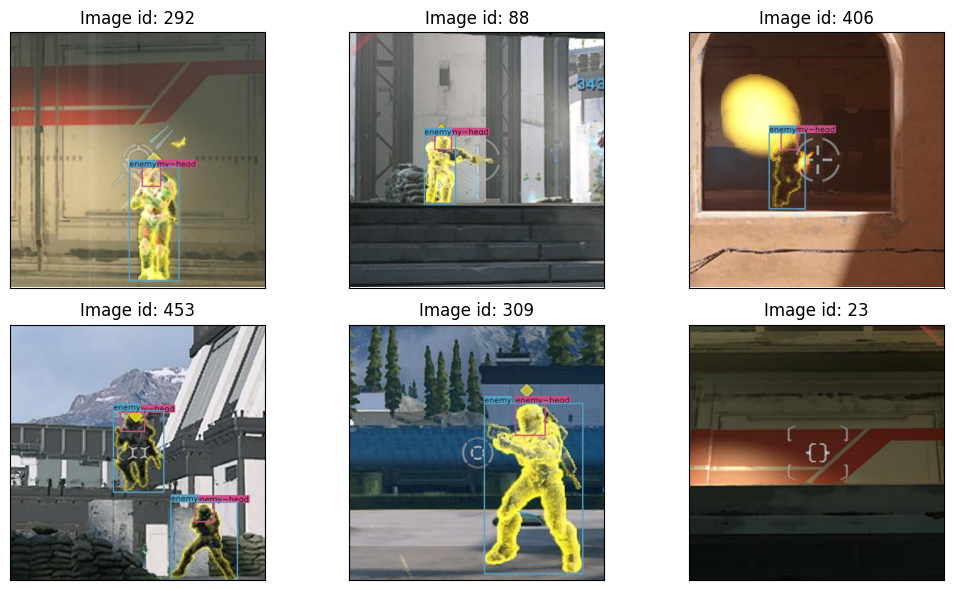

In [ ]:
plot_examples(df_train)

Создаем датасет для предобработки данных

In [ ]:
class HaloDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        df_objects = pd.json_normalize(dataframe['objects'])[["bbox", "category"]]
        df_images = pd.json_normalize(dataframe['image'])[["bytes"]]
        self.data = dataframe[["image_id"]].join(df_objects).join(df_images)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        """Загружаем данные и разметку для объекта с индексом `idx`.

        labels: List[int] Набор классов для каждого ббокса,
        boxes: List[List[int]] Набор ббоксов в формате (x_min, y_min, w, h).
        """
        row = self.data.iloc[idx]
        image = Image.open(io.BytesIO(row["bytes"]))
        image = np.array(image)

        target = {}
        target["image_id"] = row["image_id"]

        labels = [row["category"]] if isinstance(row["category"], int) else row['category']
        # Вычитаем единицу чтобы классы начинались с нуля
        labels = [label - 1 for label in labels]
        boxes = row['bbox'].tolist()

        if self.transform is not None:
            transformed = self.transform(image=image, bboxes=boxes, labels=labels)
            image, boxes, labels = transformed["image"], transformed["bboxes"], transformed["labels"]
        else:
            image = transforms.ToTensor()(image)

        target['boxes'] = torch.tensor(np.array(boxes), dtype=torch.float32)
        target['labels'] = torch.tensor(labels, dtype=torch.int64)
        return image, target

def collate_fn(batch):
    batch = tuple(zip(*batch))
    images = torch.stack(batch[0])
    return images, batch[1]

Чтобы модель не переобучалась, можно добавить больше аугментаций, весь список можно посмотреть тут [[ссылка](https://explore.albumentations.ai/)].

Какие можно использовать аугментации?
* Добавить зум `RandomResizedCrop`,
* Сделать цветовые аугментации типа `RandomBrightnessContrast` и/или `HueSaturationValue`,
* Добавить шум `GaussNoise`,
* Вырезать случайные части изображения `CoarseDropout`,
* И любые другие!

Аугментации можно комбинировать посредством `A.OneOf`, `A.SomeOf` или `A.RandomOrder`.

Хоть аугментации ограничиваются только вашей фантазией, перед обучением советуем посмотреть на результат преобразований и убедиться, что изображение ещё поддается детекции:)

In [ ]:
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = A.Compose(
    [
        # Добавляй сюда свои аугментации при необходимости!
        A.Normalize(mean=mean, std=std),
        A.SomeOf([
            A.HorizontalFlip(p=0.5),
            A.RandomBrightnessContrast(brightness_limit=0.08, contrast_limit=0.08, p=0.5),
            A.GaussNoise(std_range=(0.05, 0.1), mean_range=(0.05, 0.1), p=0.5)
        ], n=1, replace=False, p=0.8),
        ToTensorV2(),
    ],
    # Раскомментируй, если аугментации изменяют ббоксы.
    # Не забудь указать верный формат для ббоксов.
    bbox_params=A.BboxParams(format='coco', label_fields=['labels'])
)

test_transform = A.Compose(
    [
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ]
)

Не забываем инициализировать наш датасет

In [ ]:
train_dataset = HaloDataset(df_train, transform=train_transform)
test_dataset = HaloDataset(df_test, transform=test_transform)

In [ ]:
def plot_images(dataset, num_examples=6, row_figsize=(12, 3)):
    img_idx = np.random.choice(len(dataset),size=num_examples, replace=False)
    ncols = min(num_examples, 3)
    nrows = math.ceil(num_examples / ncols)
    _, axes = plt.subplots(nrows, ncols, figsize=(row_figsize[0], row_figsize[1] * nrows), tight_layout=True)
    axes = axes.ravel()

    mean_tensor = torch.tensor(mean).view(3, 1, 1)
    std_tensor = torch.tensor(std).view(3, 1, 1)

    for ix, ax in enumerate(axes):
        idx = img_idx[ix]
        img = dataset[idx][0].clone()

        img = img * std_tensor + mean_tensor
        img = torch.clip(img, 0, 1)
        img = img.permute(1, 2, 0)
        ax.imshow(img)
        ax.set_title(f"Image id: {dataset[idx][1]['image_id']}")

Посмотрим на изображения после аугментаций:

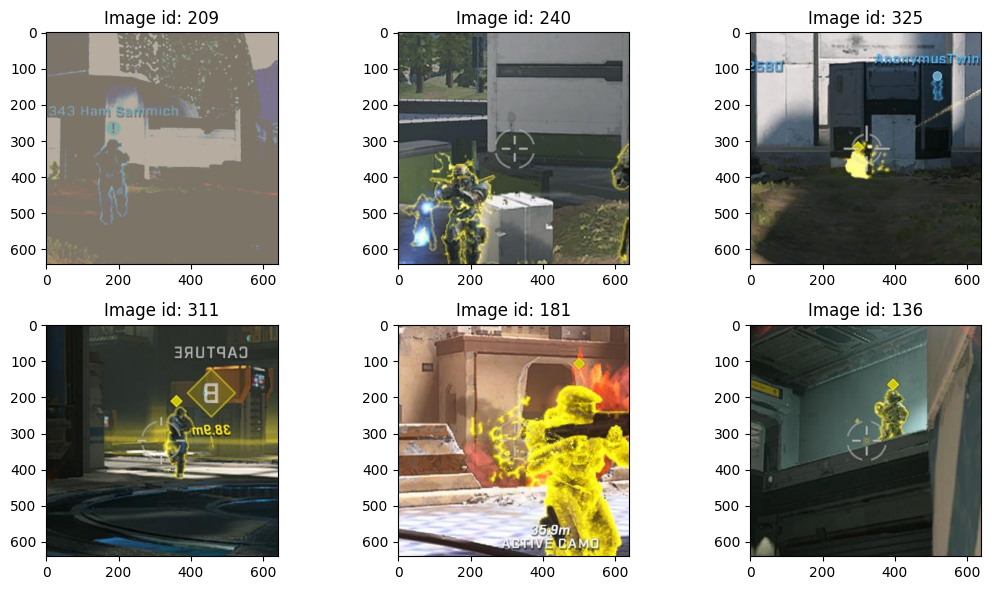

In [ ]:
plot_images(train_dataset)

## Переделываем модель [4 балла]

В семинаре мы реализовали самый базовый детектор, а сейчас настало время его улучшать.

### Backbone [1 балл]

Хорошей практикой считается размораживать несколько последних слоев в backbone, это позволяет немного улучшить качество модели. Давайте улучшим класс Backbone из лекции, добавив ему возможность разморозки __k__ последних слоев или блоков (на ваш выбор).

In [ ]:
# timm.list_models(pretrained=True)

In [ ]:
class Backbone(nn.Module):
    def __init__(self, model_name="efficientnet_b0", out_indices=(-1, -2, -3), unfreeze_last=3):
        # YOUR CODE HERE!
        super().__init__()

        self.backbone = timm.create_model(model_name, pretrained=True, features_only=True, out_indices=out_indices)

        params = list(self.backbone.parameters())
        freeze_layers_cnt = len(params) - unfreeze_last # кол-во слоев, которые будем замораживать
        for param in params[: freeze_layers_cnt]:
            param.requires_grad = False

    def forward(self, x):
        # YOUR CODE HERE!
        return self.backbone(x)

### NECK [2 балла]

Следующее улучшение коснется шеи. Предлагаем реализовать знакомую из лекции архитектуру FPN.

#### Feature Pyramid Network

<center><img src="https://user-images.githubusercontent.com/57972646/69858594-b14a6c00-12d5-11ea-8c3e-3c17063110d3.png"/></center>


* [Feature Pyramid Networks for Object Detection](https://arxiv.org/abs/1612.03144)

Она состоит из top-down пути, в котором происходит 2 вещи:
1. Увеличивается пространственная размерность фичей,
2. С помощью скипконнекшеннов, добавляются фичи из backbone модели.

Для увеличения пространственной размерности используется __nearest neighbor upsampling__, а фичи из шеи и бекбоуна суммируются.

__TIPS__:
* Можете использовать базовые классы из лекции,
* Воспользуйтесь AnchorGenerator-ом, чтобы создавать якоря сразу для нескольких выходов,
* Не забудьте использовать nn.ModuleList, если захотите сделать динамическое количество голов у модели,
* Также, можно добавить доп конволюцию (3х3 с паддингом) у каждого выхода шеи.

In [ ]:
import torch.nn as nn

In [ ]:
class Neck(nn.Module):
    """
    Feature Pyramid Network
    """
    def __init__(self, in_channels_vals, out_channels=256, extra_conv=True, use_activations=True):
        # YOUR CODE HERE
        super().__init__()

        self.layers = nn.ModuleList()
        self.extra_layers = nn.ModuleList()
        self.activation = nn.ReLU(inplace=True) if use_activations else nn.Identity()

        for in_channels in in_channels_vals:
            layer = []
            layer.append(nn.Conv2d(in_channels, out_channels, kernel_size=1))
            layer.append(nn.BatchNorm2d(out_channels))
            layer.append(self.activation)
            self.layers.append(nn.Sequential(*layer))

            extra_layer = []
            if extra_conv:
                extra_layer.append(nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1))
                extra_layer.append(nn.BatchNorm2d(out_channels))
                extra_layer.append(self.activation)
                self.extra_layers.append(nn.Sequential(*extra_layer))
            else:
                self.extra_layers.append(nn.Identity())

        self.upsample = nn.Upsample(scale_factor=2, mode='nearest')

    def forward(self, features):
        # YOUR CODE HERE
        layers_features = [layer(feature) for layer, feature in zip(self.layers, features)]

        num = len(features)
        result = [None for i in range(num)]
        result[-1] = layers_features[-1]

        for i in range(num - 2, -1, -1):
            up = self.upsample(result[i + 1])
            if up.shape[-2:] != layers_features[i].shape[-2:]:
                up = F.interpolate(result[i + 1], size=layers_features[i].shape[-2:], mode='nearest')
            result[i] = layers_features[i] + up

        output = [layer(feature) for layer, feature in zip(self.extra_layers, result)]

        return output

### Head [1 балл]

В качестве головы можно выбрать __один из двух__ вариантов:

#### 1. Decoupled Head

Реализовать Decoupled Head из [YOLOX](https://arxiv.org/abs/2107.08430).
<center><img src="https://i.ibb.co/BVtBR2R3/Decoupled-head.jpg"/></center>

**TIP**: Возьмите за основу голову из семинара, тк она сильно похожа на Decoupled Head.

Изменять количество параметров у шей на разных уровнях не обязательно.

#### 2. Confidence score free head

Нужно взять за основу голову из семинара и полностью убрать предсказание confidence score. Чтобы модель предсказывала только 2 группы: ббоксы и классы.

Есть следующие способы удаления confidence score:
* Добавление нового класса ФОН. Обычно его обозначают нулевым классом.
* Присваивание ббоксам БЕЗ объекта вектор из нулей в качестве таргета.

Выберете тот, который вам больше нравится и будьте внимательны при расчете лосса!

**Важно!** Удаление confidence score повлияет на следующие методы из семинара:
* target_assign
* ComputeLoss
* _filter_predictions

Будем реализовывавать Decoupled Head

In [ ]:
class Head(nn.Module):
    """
    Decoupled Head
    """
    def __init__(self, in_channels, num_anchors, num_classes, out_channels=256):
        # YOUR CODE HERE
        super().__init__()
        self.num_classes = num_classes
        self.num_anchors = num_anchors

        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        self.cls_head = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, num_anchors * num_classes, kernel_size=1),
        )
        self.reg_head = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, num_anchors * 4, kernel_size=1),
        )
        self.conf_head = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, num_anchors * 1, kernel_size=1),
        )

    def forward(self, x):
        # YOUR CODE HERE
        x = F.relu(self.conv(x))
        cls_logits = self.cls_head(x)
        bbox_preds = self.reg_head(x)
        conf_scores = self.conf_head(x)

        return cls_logits, bbox_preds, conf_scores

Теперь можно снова реализовать класс детектора с учетом всех частей выше!

In [ ]:
class Detector(nn.Module):
    # YOUR CODE HERE
    def __init__(self,
                 backbone_model_name="efficientnet_b0",
                 unfreeze_cnt=3,
                 neck_n_channels=256,
                 num_classes=4,
                 anchor_sizes=((32, 64, 128), ),
                 anchor_ratios=((0.5, 1.0, 2.0), ),
                 input_size=(640, 640),
        ):
        super().__init__()
        self.num_classes = num_classes
        # создаем backbone с 3 выходами
        self.backbone = Backbone(backbone_model_name, out_indices=(-1, -2, -3), unfreeze_last=unfreeze_cnt)
        in_channels_list = self.backbone.backbone.feature_info.channels()
        # создаем шею
        self.neck = Neck(in_channels_list, out_channels=neck_n_channels)

        anchor_sizes *= len(in_channels_list)
        anchor_ratios *= len(in_channels_list)
        # считаем количество якорей в каждой ячейке выходной фичемапы
        num_anchors = len(anchor_sizes[0]) * len(anchor_ratios[0])
        self.head = Head(in_channels=neck_n_channels, num_anchors=num_anchors, num_classes=num_classes)

        # генерируем якоря
        anchor_generator = AnchorGenerator(sizes=anchor_sizes, aspect_ratios=anchor_ratios)
        # узнаем размер выходной фичемапы
        reduction = self.backbone.backbone.feature_info.reduction()
        grid_sizes = [[input_size[0] // r, input_size[1] // r] for r in reduction]
        strides = [[r, r] for r in reduction]

        # Расчитываем координаты якорей в каждой точке выходной фичемапы.
        ###
        # Якоря хранятся в формате (x_min, y_min, x_max, y_max)!
        ###
        anchors_per_level = anchor_generator.grid_anchors(grid_sizes, strides=strides)
        anchors = torch.cat(anchors_per_level, dim=0)

        # Заранее считаем координаты якорей в формате (x_center, y_center, w, h)
        # Это пригодится для расчета лосса
        anchor_centers = (anchors[:, :2] + anchors[:, 2:]) / 2
        anchor_sizes_tensor = (anchors[:, 2:] - anchors[:, :2])

        self.register_buffer("anchors", anchors)
        self.register_buffer("anchor_centers", anchor_centers.unsqueeze(0))
        self.register_buffer("anchor_sizes", anchor_sizes_tensor.unsqueeze(0))

    def forward(self, x):
        # Пропускаем картинку через всю сеть
        features = self.backbone(x)
        neck_features = self.neck(features)
        cls_list, bbox_list, conf_list = [], [], []
        N = x.shape[0]

        for feature in neck_features:
            cls_logits, bbox_preds, conf_scores = self.head(feature)

            # Преобразуем сырые выходы модели в формат, в котором будет удобно считать лосс
            # cls_logits - [N, NUM_ANCHORS * NUM_CLASSES, W, H]
            # bbox_preds - [N, NUM_ANCHORS * 4, W, H]
            # conf_scores - [N, NUM_ANCHOTS * 1, W, H]
            cls_logits = cls_logits.permute(0, 2, 3, 1).contiguous()
            cls_logits = cls_logits.view(N, -1, self.head.num_classes) # [N, NUM_ANCHORS * W * H, NUM_CLASSES]
            cls_list.append(cls_logits)

            bbox_preds = bbox_preds.permute(0, 2, 3, 1).contiguous()
            bbox_preds = bbox_preds.view(N, -1, 4) # [N, NUM_ANCHORS * W * H, 4]
            bbox_list.append(bbox_preds)

            conf_scores = conf_scores.permute(0, 2, 3, 1).contiguous()
            conf_scores = conf_scores.view(N, -1, 1) # [N, NUM_ANCHORS * W * H, 1]
            conf_list.append(conf_scores)

        cls_logits = torch.cat(cls_list, dim=1)
        bbox_preds = torch.cat(bbox_list, dim=1)
        conf_scores = torch.cat(conf_list, dim=1)

        if self.training:
            # В процессе тренировки возвращаем просто смещения и логиты
            return bbox_preds, conf_scores, cls_logits

        # Если мы делаем предсказание, сразу считаем итоговый ббокс и вероятности
        # Модель предсказывает ббоксы в формате (x_min, y_min, w, h)
        bboxes = self.decode_bboxes(bbox_preds)
        confidence = torch.sigmoid(conf_scores)
        cls_probs = torch.softmax(cls_logits, dim=-1)

        return bboxes, confidence, cls_probs

    def decode_bboxes(self, bbox_offsets):
        """Используя предсказанные смещения, считаем предсказанные ббоксы по формулам из YOLOv3.

        Боксы возвращаются в формате (x_min, y_min, w, h).
        """
        tx = bbox_offsets[:, :, 0]
        ty = bbox_offsets[:, :, 1]
        tw = bbox_offsets[:, :, 2]
        th = bbox_offsets[:, :, 3]

        center_x = self.anchor_centers[:, :, 0] + torch.sigmoid(tx) * self.anchor_sizes[:, :, 0]
        center_y = self.anchor_centers[:, :, 1] + torch.sigmoid(ty) * self.anchor_sizes[:, :, 1]

        w = torch.exp(tw) * self.anchor_sizes[:, :, 0]
        h = torch.exp(th) * self.anchor_sizes[:, :, 1]

        x_min = center_x - w / 2
        y_min = center_y - h / 2

        return torch.stack([x_min, y_min, w, h], dim=-1)

## Label assignment [3 балла]
В этой секции предлагается заменить функцию `assign_target` на более современный алгоритм который называется Task alignment learning.

Он описан в статье [TOOD](https://arxiv.org/abs/2108.07755) в секции 3.2. Для удобства вот его основные шаги:

1. Посчитать значение метрики для каждого предсказанного ббокса:
    
$$t = s^\alpha * u^\beta$$
    
где,
* $s$ — classification score, или вероятность принадлежности предсказанного ббокса к классу реального ббокса (**GT**);
* $u$ — IoU между предсказанным и реальным ббоксами;
* $\alpha,\ \beta$ — нормализационные константы, обычно $\alpha = 6.0, \ \beta = 1.0$.
    
2. Отфильтровать предсказания на основе **GT**.

    Для якорных детекторов, обычно, выбираются только те предсказания, центры якорей которых находятся внутри GT.
4. Для каждого **GT** выбрать несколько (обычно 5 или 13) самых подходящих предсказаний.
5. Если предсказание рассматривается в качестве подходящего для нескольких **GT** — выбрать **GT** с наибольшим пересечением по IoU.


**BAЖНО**: если будете использовать Runner из лекции, не забудьте поменять параметры  в `self.assign_target_method` в методе `_run_train_epoch`.

In [ ]:
def TAL_assigner(anchors, gt_boxes, gt_labels, num_classes, clf_scores, iou_scores, alpha=6.0, beta=1.0, top=5):
    # YOUR CODE HERE!

    device = anchors.device
    A = anchors.size(0)
    G = gt_boxes.size(0)

    gt_labels_clamped = gt_labels.clamp(0, num_classes - 1)
    s = clf_scores[:, gt_labels_clamped]
    u = iou_scores
    t = (s ** alpha) * (u ** beta)

    # gt (x, y, w, h) -> xyxy
    x_gt = gt_boxes[:, 0]
    y_gt = gt_boxes[:, 1]
    w_gt = gt_boxes[:, 2]
    h_gt = gt_boxes[:, 3]
    x1_gt = x_gt
    y1_gt = y_gt
    x2_gt = x_gt + w_gt
    y2_gt = y_gt + h_gt
    gt_boxes_xyxy = torch.stack([x1_gt, y1_gt, x2_gt, y2_gt], dim=-1)

    # центры якорей
    anchor_centers = (anchors[:, :2] + anchors[:, 2:]) / 2.0
    x_centers = anchor_centers[:, 0].unsqueeze(1)
    y_centers = anchor_centers[:, 1].unsqueeze(1)

    x1 = gt_boxes_xyxy[:, 0].unsqueeze(0)
    y1 = gt_boxes_xyxy[:, 1].unsqueeze(0)
    x2 = gt_boxes_xyxy[:, 2].unsqueeze(0)
    y2 = gt_boxes_xyxy[:, 3].unsqueeze(0)

    # фильтрация на основе gt
    inside_x = (x_centers >= x1) & (x_centers <= x2)
    inside_y = (y_centers >= y1) & (y_centers <= y2)
    inside_gt_mask = inside_x & inside_y

    eps = 1e-9
    t = torch.where(
        (inside_gt_mask & (u > eps)),
        t,
        torch.full_like(t, -1e8),
    )

    # для каждого gt берем top самых подходящих предсказаний
    top = min(top, A)
    topk_vals, topk_ids = t.top(k=top, dim=0)

    valid_mask = topk_vals > 0

    matching_matrix = torch.zeros_like(t, dtype=torch.bool)
    matching_matrix.scatter_(0, topk_ids, True)
    matching_matrix = matching_matrix & (t > 0)

    # выбираем  gt с max iou
    anchor_assigned_gt_count = matching_matrix.sum(dim=1)
    multiple_match_mask = anchor_assigned_gt_count > 1

    if multiple_match_mask.any():
        iou_for_matching = torch.where(
            matching_matrix,
            u,
            torch.full_like(u, -1e8),
        )

        best_gt_iou, best_gt_idx = iou_for_matching.max(dim=1)

        new_matching_matrix = torch.zeros_like(matching_matrix)
        has_match = best_gt_iou > 0
        row_idx = torch.nonzero(has_match, as_tuple=False).squeeze(1)
        col_idx = best_gt_idx[has_match]
        new_matching_matrix[row_idx, col_idx] = True
        matching_matrix = new_matching_matrix

    assigned_labels = torch.full(
        (A,), -1, device=device, dtype=torch.long
    )

    assigned_bboxes = torch.zeros(
        (A, 4), device=device, dtype=anchors.dtype
    )  # COCO (x, y, w, h)

    assigned_scores = torch.zeros(
        (A, num_classes), device=device, dtype=anchors.dtype
    )

    for gt_idx in range(G):
        pos_mask = matching_matrix[:, gt_idx]
        if not pos_mask.any():
            continue

        gt_box_coco = gt_boxes[gt_idx]
        gt_label = gt_labels_clamped[gt_idx].item()

        pos_indices = torch.nonzero(pos_mask, as_tuple=False).squeeze(1)

        # bbox-таргеты
        assigned_bboxes[pos_indices] = gt_box_coco

        # метки
        assigned_labels[pos_indices] = gt_label

        # веса для классификационного лосса:
        t_pos = t[pos_indices, gt_idx]
        pos_weight = t_pos / (t_pos.sum() + 1e-6)

        assigned_scores[pos_indices, gt_label] = pos_weight

    fg_mask = assigned_labels >= 0

    return assigned_bboxes, assigned_labels, assigned_scores, fg_mask


### DIoU [1]

Вместо SmoothL1, который используется в семинаре, реализуем лосс, основанный на пересечении ббоксов. В качестве тренировки давайте напишем Distance Intersection over Union (DIoU).

<center><img src=https://wikidocs.net/images/page/163613/Free_Fig_5.png></center>

Для его реализации разобъем задачу на части:

**1. Реализуем IoU:**

Пусть даны координаты для предсказанного ($B^p$) и истинного ($B^g$) ббоксов в формате XYXY или VOC PASCAL (левый верхний и правый нижний углы):

$B^p=(x^p_1, y^p_1, x^p_2, y^p_2)$, $B^g=(x^g_1, y^g_1, x^g_2, y^g_2)$, тогда алгоритм расчета будет следующий:

    1. Найдем площади обоих ббоксов:
$$ A^p = (x^p_2 - x^p_1) * (y^p_2 - y^p_1) $$
$$ A^g = (x^g_2 - x^g_1) * (y^g_2 - y^g_1) $$

    2. Посчитаем пересечение между ббоксами:

Тут мы предлагаем вам подумать как в общем виде можно расчитать размеры ббокса, который будет являться пересечением $B^p$ и $B^g$, а затем посчитать его площадь:

$$x^I_1 = max\{x^p_1, x^g_1\} \qquad y^I_1 = max\{y^p_1, y^g_1\}$$
$$x^I_2 = min\{x^p_2, x^g_2\} \qquad y^I_2 = min\{y^p_2, y^g_2\}$$

В общем виде, площать будет записываться следующим образом:

Если $x^I_2 > x^I_1$ & $y^I_2 > y^I_1$, тогда:

$$I = (x^I_2 - x^I_1) * (y^I_2 - y^I_1)$$

Иначе, $I = 0$.

    3. Считаем объединение ббоксов.

Мы можем посчитать эту площадь как сумму площадей двух ббоксов минус площадь пересечения (тк мы считаем её два раз в сумме площадей):

$$U = A^p + A^g - I$$

    4. Вычисляем IoU.

$$IoU = \frac{I}{U}$$

**2. Посчитаем диагональ выпуклой оболочки:**

Для расчета диагонали, сначала выпишите координаты верхнего левого и правого нижнего углов. Подумайте, чему будут равны эти координаты в общем случае?

$$x^c_1 = min\{x^p_1, x^g_1\} \qquad y^c_1 = min\{y^p_1, y^g_1\}$$
$$x^c_2 = max\{x^p_2, x^g_2\} \qquad y^c_2 = max\{y^p_2, y^g_2\}$$

Подсказка: Нарисуйте несколько вариантов пересечений предсказания и GT на бумажке, и выпишите координаты для выпуклой оболочки.

Тогда квадрат диагонали можно посчитать по формуле:

$$c^2 = (x^c_2 - x^c_1)^2 + (y^c_2 - y^c_1)^2$$

**3. Рассчитаем расстояние между цетрами ббоксов:**

Сначала находим координаты центров каждого из ббоксов (если ббоксы в формате YOLO, то и считать ничего не нужно), затем считаем Евклидово расстояние между центрами $d$.

Собираем все части вместе и считаем лосс по формуле:

$$ DIoU = 1 - IoU + \frac{d^2}{c^2}$$

Помните, что пар ббоксов может быть много! Возвращайте усредненное значение лосса.

In [ ]:
from torchvision.ops import distance_box_iou_loss, box_iou

In [ ]:
def gen_bbox(num_boxes=10):
    min_corner = torch.randint(0, 100, (num_boxes, 2))
    max_corner = torch.randint(50, 150, (num_boxes, 2))

    for i in range(2):
        wrong_order = min_corner[:, i] > max_corner[:, i]
        if wrong_order.any():
            min_corner[wrong_order, i], max_corner[wrong_order, i] = max_corner[wrong_order, i], min_corner[wrong_order, i]
    return torch.cat((min_corner, max_corner), dim=1)

In [ ]:
pred_boxes = gen_bbox(num_boxes=100)
true_boxes = gen_bbox(num_boxes=100)

In [ ]:
print(f"DIoU: {distance_box_iou_loss(pred_boxes, true_boxes, reduction="mean").item():.4f}")

DIoU: 1.0040


In [ ]:
def iou_score(pred_box, gt_box):
    x1_pred, y1_pred, x2_pred, y2_pred = pred_box
    x1_true, y1_true, x2_true, y2_true = gt_box

    pred_area = (x2_pred - x1_pred) * (y2_pred - y1_pred)
    true_area = (x2_true - x1_true) * (y2_true - y1_true)

    x1_tl = torch.max(x1_pred, x1_true)
    y1_tl = torch.max(y1_pred, y1_true)

    x2_br = torch.min(x2_pred, x2_true)
    y2_br = torch.min(y2_pred, y2_true)

    if x2_br < x1_tl or y2_br < y1_tl:
        return torch.tensor(0, dtype=float)

    inter = (x2_br - x1_tl) * (y2_br - y1_tl)
    union = pred_area + true_area - inter
    iou = inter / union

    return iou

In [ ]:
def diou_score(pred_box, gt_box):
    x1_pred, y1_pred, x2_pred, y2_pred = pred_box
    x1_true, y1_true, x2_true, y2_true = gt_box

    x1_c = torch.min(x1_pred, x1_true)
    y1_c = torch.min(y1_pred, y1_true)
    x2_c = torch.max(x2_pred, x2_true)
    y2_c = torch.max(y2_pred, y2_true)

    c_power = (x2_c - x1_c) ** 2 + (y2_c - y1_c) ** 2

    x_center_pred = (x1_pred + x2_pred) / 2
    y_center_pred = (y1_pred + y2_pred) / 2
    x_center_true = (x1_true + x2_true) / 2
    y_center_true = (y1_true + y2_true) / 2

    d_power = (x_center_pred - x_center_true) ** 2 + (y_center_pred - y_center_true) ** 2

    iou = iou_score(pred_box, gt_box)
    diou = 1 - iou + d_power / c_power

    return diou

In [ ]:
def diou_loss(pred_boxes, gt_boxes):
    # TODO
    diou_values = []
    for p, t in zip(pred_boxes, gt_boxes):
        diou_values.append(diou_score(p, t))

    diou_values = torch.stack(diou_values)
    return diou_values.mean()

In [ ]:
diou_loss(pred_boxes, true_boxes)

tensor(1.0040, dtype=torch.float64)

In [ ]:
# проверим что написанный лосс выдает те же результаты что и лосс из торча.
assert np.isclose(diou_loss(pred_boxes, true_boxes), distance_box_iou_loss(pred_boxes, true_boxes, reduction="mean"))

## Кто больше? [5 баллов]

Наконец то мы дошли до самый интересной части. Тут мы раздаем очки за mAP'ы!

Все что вы написали выше вам поможет улучшить качество итогового детектора, настало время узнать насколько сильно :)

За достижения порога по mAP на тестовом наборе вы получаете баллы:
* 0.05 mAP [1]
* 0.1 mAP [2]
* 0.2 mAP [5]


**TIPS**:
1. На семинаре мы специально не унифицировали формат ббоксов между методами, чтобы обратить ваше внимание что за этим нужно следить. Чтобы было проще, сразу унифицируете формат по всему ноутбуку. Советуем использовать формат xyxy, тк IoU и NMS из torch используют именно этот формат. (Не забудьте поменять формат у таргета в `HaloDataset`).

2. Попробуйте перейти к IoU-based лоссу при обучении. То есть обучать не смещения, а сразу предсказывать ббокс.

3. Поэксперементируйте с подходами target assignment'а в процессе обучения. Например, можно на первых итерациях использовать обычный метод, а затем подключить TAL.

4. Добавьте аугментаций!

Можно взять [albumentations](https://albumentations.ai/docs/getting_started/bounding_boxes_augmentation/), библиотеку, которую мы использовали всеминаре. Или базовые аугментации из торча [тык](https://pytorch.org/vision/main/transforms.html). Если будете использовать торч, не забудте про ббоксы, transforms из коробки не будет их агументировать.

5. Можете реализовать другую шею, которую мы обсуждали на лекции [Path Aggregation Network](https://arxiv.org/abs/1803.01534) она точно улучшит ваше итоговое качество.

6. Попробуйте добавлять различные блоки из YOLO архитектур в шею вместо единичных конволюционных слоев. (Например, замените конволюции 3х3 на CSP блоки).

7. Попробуйте заменить NMS на другой метод (WeightedNMS, SoftNMS, etc.). Немного ссылок:
    * Статья про SoftNMS [тык](https://arxiv.org/pdf/1704.04503)
    * Статья про WeightedNMS [тык](https://openaccess.thecvf.com/content_ICCV_2017_workshops/papers/w14/Zhou_CAD_Scale_Invariant_ICCV_2017_paper.pdf)
    * Есть их реализация, правда на нумбе [git](https://github.com/ZFTurbo/Weighted-Boxes-Fusion?tab=readme-ov-file)

8. Не бойтесь эксперементировать и удачи!

Также, напишите развернутые ответы на следующие вопросы:

**Questions:**
1. Какой метод label assignment'a помогает лучше обучаться модели? Почему?
2. Какое из сделаных вами улучшений внесло наибольший вклад в качество модели? Как вы думаете, почему это произошло?
3. Какое из сделанных вами улучшений вообще не изменило метрику? Как вы думаете, почему это произошло?

In [ ]:
# Место для обучения, валидации и экспериментов!

In [ ]:
def safe_logit(x):
    """ Безопасный расчет logit'ов. """
    eps = 1e-6
    x = torch.clamp(x, eps, 1 - eps)
    return torch.log(x / (1 - x))

def get_target_offset(anchor_box, gt_box):
    """ Расчитываем таргет как желаемые смещения от якорей до GT.

    anchor_box: torch.Tensor в формате (x_min, y_min, x_max, y_max),
    gt_box: torch.Tensor в формате (x_min, y_min, x_max, y_max).
    """
    # Конвертируем GT в формат (x_center, y_center), (w, h)
    gt_center = (gt_box[:2] + gt_box[2:]) / 2
    gt_size = gt_box[2:] - gt_box[:2]

    # Конвертируем якоря в формат (x_center, y_center), (w, h)
    anchor_center = (anchor_box[:2] + anchor_box[2:]) / 2
    anchor_size = anchor_box[2:] - anchor_box[:2]

    # Вычисляем значения смещений для положительных ббоксов
    tx = (gt_center[0] - anchor_center[0]) / anchor_size[0]
    ty = (gt_center[1] - anchor_center[1]) / anchor_size[1]
    target_tx = safe_logit(tx)
    target_ty = safe_logit(ty)

    target_tw = torch.log(gt_size[0] / anchor_size[0])
    target_th = torch.log(gt_size[1] / anchor_size[1])
    return torch.tensor([target_tx, target_ty, target_tw, target_th]).to(anchor_box.device)

In [ ]:
def assign_target(anchors, gt_boxes, gt_labels, num_classes, pos_th=0.6, neg_th=0.3):
    """ Для каждого GT находим якоря, которые будут участвовать в расчете лосса по следующему алгоритму:
    1. Положительные якоря - якоря у которых IoU с GT >= `pos_th`,
    2. Игнорируемые якоря - `neg_th` <= IoU c GT < `pos_th`,
    3. Отрицательные якоря - IoU c GT < `neg_th`.
    4. Если для GT не нашлось ни одного якоря, назначаем GT якорь с самым большим IoU.

    Параметры
    ---------
    anchors : list[list[float]]
        Набор якорей для выходной фичемапы, размер (NUM_ANCHORS * W * H, 4)
    gt_boxes : list[list[float]]
        Набор истинных ббоксов на изображении, размер (N_GT, 4)
    gt_labels : list[int]
        Набор лейблов для GT, размер (N_GT, )
    num_classes : int
        Количество классов в датасете
    pos_th : float
        Минимальная граница по IoU между якорем и GT после которой якорь считается положительным.
    neg_th : float
        Верхняя граница по IoU между якорем и GT когда якорь считается отрицательным.

    Returns
    -------
    target_offsets: Массив, содержащий истинные смещения для положительных якорей, 0 для всех остальных
    target_objectness: Массив, содержащий тип каждого якоря (1 - положительный, 0 - отрицательный, -1 - игнорируемый)
    target_cls: Массив, содержащий ohe классы для каждого якоря. Для всех, кроме положительных якорей, класс не указан.
    """
    num_anchors = anchors.shape[0]
    target_objectness = torch.zeros(num_anchors, device=anchors.device)
    target_offsets = torch.zeros((num_anchors, 4), device=anchors.device)
    target_cls = torch.zeros((num_anchors, num_classes), device=anchors.device)
    # Если на изображении нет объектов, возвращаем пустые списки
    if gt_boxes.numel() == 0:
        return target_offsets, target_objectness, target_cls
    # box_iou работает с форматом ббоксов (x_min, y_min, x_max, y_max)
    # Якоря находятся в нужном формате, а GT - нет, тк имеет формат (x_min, y_min, w, h)
    # Переведем GT боксы в нужный формат
    gt_xyxy = gt_boxes.clone()
    gt_xyxy[:, 2:] = gt_xyxy[:, :2] + gt_xyxy[:, 2:]
    # Считаем iou между всеми якорями и всеми GT
    ious = box_iou(anchors, gt_xyxy) # [num_anchors, num_gt]
    # Находим самый оптимальный GT для каждого якоря
    best_iou, best_gt_idx = ious.max(dim=1)
    # Отмечаем якоря, которые будут пропущены при расчете лосса
    ignore_mask = (best_iou >= neg_th) & (best_iou < pos_th)
    target_objectness[ignore_mask] = -1

    # Отмечаем якоря, для которых будет считаться локализационный лосс
    pos_mask = best_iou >= pos_th
    pos_indices = pos_mask.nonzero(as_tuple=True)[0]
    for pos in pos_indices:
        gt_idx = best_gt_idx[pos]
        gt_box = gt_xyxy[gt_idx]
        anchor_box = anchors[pos]

        target_offsets[pos] = get_target_offset(anchor_box, gt_box)
        target_objectness[pos] = 1
        target_cls[pos, gt_labels[gt_idx]] = 1

    # Присваиваем предсказание с самым большим IoU для GT
    # у которых не нашлось ни оного предсказания
    for gt_idx in range(gt_xyxy.shape[0]):
        if not((target_objectness == 1) & (best_gt_idx == gt_idx)).any():
            best_anchor_idx = torch.argmax(ious[:, gt_idx])
            target_offsets[best_anchor_idx] = get_target_offset(anchors[best_anchor_idx], gt_xyxy[gt_idx])
            target_objectness[best_anchor_idx] = 1
            target_cls[best_anchor_idx, gt_labels[gt_idx]] = 1
    return target_offsets, target_objectness, target_cls

In [ ]:
class ComputeLoss:
    """ Базовый расчет лосса.

    Параметры
    ---------
    bbox_loss : Локализационная часть лосса
    obj_loss : Лосс для Confidence score
    cls_loss : Классификационная часть лосса
    weight_bbox, weight_obj, weight_cls : Константы для баллансировки частей лосса
    """
    def __init__(self,
            bbox_loss=None, obj_loss=None, cls_loss=None,
            weight_bbox=5, weight_obj=1, weight_cls=1
        ):
        self.bbox_loss = nn.SmoothL1Loss() if bbox_loss is None else bbox_loss
        self.obj_loss = nn.BCEWithLogitsLoss() if obj_loss is None else obj_loss
        self.cls_loss = nn.BCEWithLogitsLoss() if cls_loss is None else cls_loss
        self.weight_bbox = weight_bbox
        self.weight_obj = weight_obj
        self.weight_cls = weight_cls

    def __call__(self, predicts, targets):
        """ Расчет лосса для пары (предсказание, таргет)

        Параметры
        ---------
        predicts : Предсказания модели для одной картинки: Смещения, objectness score и логиты для классов
        targets : Gt значения для расчета лосса, а именно: GT смещения, GT objectness score и GT ohe классы
        """
        pred_offsets, pred_obj_logits, pred_cls_logits = predicts
        target_boxes, target_obj, target_cls = targets
        # Confidence score считается только для предсказаний соотв отрицательным и положительным якорям
        valid_mask = target_obj != -1
        loss_obj = self.obj_loss(pred_obj_logits[valid_mask], target_obj[valid_mask])

        # Локализационная и классификационные части считаются для предсказаинй соотв положительным якорям
        pos_mask = target_obj == 1
        if pos_mask.sum() > 0:
            loss_cls = self.cls_loss(pred_cls_logits[pos_mask], target_cls[pos_mask])
            loss_bbox = self.bbox_loss(pred_offsets[pos_mask], target_boxes[pos_mask])
        else:
            loss_cls = torch.tensor(0.0, device=pred_offsets.device)
            loss_bbox = torch.tensor(0.0, device=pred_offsets.device)
        return self.weight_bbox * loss_bbox + self.weight_obj * loss_obj + self.weight_cls * loss_cls

In [ ]:
class Runner:
    """ Базовый класс для обучения и валидации модели.

    Параметры
    ---------
    model : torch модель, которая будет обучаться.
    compute_loss : экземпляр класса ComputeLoss (или другого с реализованным методом __call__).
    optimizer : torch optimizer
    train_dataloader : torch dataloader семплирующий данные для обучения модели.
    assign_target_method : callable, который решает задачу сопоставления якорей и таргета (например, assign_target)
    deivce : девайс на котором будет происходить обучения, по дефолту "cpu"
    scheduler : torch scheduler
    assign_target_kwargs : доп параметры для функции в `assign_target_method`,
    val_dataloader : torch dataloader загружающий валидационные данные.
    score_threshold : При расчете метрики на валидации, все предсказания,
        с (confidence score * cls_probs) < score_threshold будут проигнорированны.
    nms_threshold : Предсказания, имеющие пересечение по IoU >= nms_threshold будут считаться одним предсказанием.
    max_boxes_per_cls : Максимальное количество ббоксов на изображение для одного класса после фильтрации по `score_threshold`.
    """
    def __init__(self, model, compute_loss, optimizer, train_dataloader, assign_target_method, device=None,
                 scheduler=None, assign_target_kwargs=None,
                 val_dataloader=None, val_every=5, score_threshold=0.1, nms_threshold=0.5, max_boxes_per_cls=8):
        self.model = model
        self.compute_loss = compute_loss
        self.optimizer = optimizer
        self.train_dataloader = train_dataloader
        assign_target_kwargs = {} if assign_target_kwargs is None else assign_target_kwargs
        self.assign_target_method = partial(assign_target_method, **assign_target_kwargs)
        self.device = "cpu" if device is None else device
        self.scheduler = scheduler

        # Валидационные параметры
        self.val_dataloader = val_dataloader
        self.val_every = val_every
        self.score_threshold = score_threshold
        self.nms_threshold = nms_threshold
        self.max_boxes_per_cls = max_boxes_per_cls

        # Вспомогательные массивы
        self.batch_loss = []
        self.epoch_loss = []
        self.val_metric = []

    def _run_train_epoch(self, dataloader, verbose=True):
        """ Обучить модель одну эпоху на данных из `dataloader` """
        self.model.train()
        batch_loss = []
        for images, targets in (pbar := tqdm(dataloader, desc=f"Process train epoch", leave=False)):
            images = images.to(self.device)
            outputs = self.model(images)

            anchors = self.model.anchors.view(-1, 4)
            accum_loss = 0.0
            for ix in range(images.shape[0]):
                gt_boxes = targets[ix]['boxes'].to(self.device)
                gt_labels = targets[ix]['labels'].to(self.device)
                # выбираем какие якоря будут использоваться при расчете лосса.
                assigned_targets = self.assign_target_method(anchors, gt_boxes, gt_labels,
                                                             num_classes=model.num_classes)
                # Считаем лосс на основании предсказаний модели и таргетов.
                outputs_ixs = [out[ix] for out in outputs]
                loss = self.compute_loss(outputs_ixs, assigned_targets)
                accum_loss += loss
            accum_loss = accum_loss / images.shape[0]
            batch_loss.append(accum_loss.cpu().detach().item())

            # Делаем шаг оптимизатора после расчета лосса для всех элементов батча
            self.optimizer.zero_grad()
            accum_loss.backward()
            self.optimizer.step()
        # Обновляем описание tqdm бара усредненным значением лосса за предыдущй батч
            if verbose:
                pbar.set_description(f"Current batch loss: {batch_loss[-1]:.4}")
        return batch_loss

    def train(self, num_epochs=10, verbose=True):
        """ Обучаем модель заданное количество эпох. """
        val_desc = ""
        for epoch in (epoch_pbar := tqdm(range(1, num_epochs+1), desc="Train epoch", total=num_epochs)):
            # Обучаем модель одну эпоху
            loss = self._run_train_epoch(self.train_dataloader, verbose=verbose)
            self.batch_loss.extend(loss)
            self.epoch_loss.append(np.mean(self.batch_loss[-len(self.train_dataloader):]))

            # Делаем валидацию, если был передан валидационный датасет
            if self.val_dataloader is not None and epoch % self.val_every == 0:
                val_metric = self.validate()
                self.val_metric.append(val_metric)
                val_desc = f" Val {val_metric:.4}"

            # Обновляем описание tqdm бара усредненным значением лосса за предыдую эпоху
            if verbose:
                epoch_pbar.set_description(f"Last epoch loss: Train {self.epoch_loss[-1]:.4}" + val_desc)
            # Делаем шаг scheduler'a если он был передан
            if self.scheduler is not None:
                self.scheduler.step()

    @torch.no_grad()
    def validate(self, dataloader=None):
        """ Метод для валидации модели. Если dataloader не передан, будет использоваться self.val_dataloder.
        Возвращает mAP (0.5 ... 0.95).
        """
        self.model.eval()
        dataloader = self.val_dataloader if dataloader is None else dataloader
        # Считаем метрику mAP с помощью функции из torchmetrics
        metric = MeanAveragePrecision(box_format="xywh", iou_type="bbox")
        for images, targets in tqdm(dataloader, desc="Running validation", leave=False):
            images = images.to(self.device)
            outputs = self.model(images)
            predicts = _filter_predictions(outputs, self.score_threshold, self.nms_threshold,
                                           max_boxes_per_cls=self.max_boxes_per_cls, return_type="torch")
            metric.update(predicts, targets)
        return metric.compute()["map"].item()

    def plot_loss(self, row_figsize=3):
        nrows = 2 if self.val_metric else 1
        _, ax = plt.subplots(nrows, 1, figsize=(12, row_figsize*nrows), tight_layout=True)
        ax = np.array([ax]) if not isinstance(ax, np.ndarray) else ax
        ax[0].plot(self.batch_loss, label="Train batch Loss", color="tab:blue")
        ax[0].plot(np.arange(1, len(self.batch_loss)+1, len(self.train_dataloader)), self.epoch_loss,
                   color="tab:orange", label="Train epoch Loss")
        ax[0].grid()
        ax[0].set_title("Train Loss")
        ax[0].set_xlabel("Number of Iterations")
        ax[0].set_ylabel("Loss")
        if self.val_metric:
            ax[1].plot(np.arange(self.val_every, len(self.batch_loss)+1, len(self.val_dataloader) * self.val_every),
                       np.array(self.val_metric) * 100, color="tab:green", label="Validation mAP")
            ax[1].grid()
            ax[1].set_title("Valiation mAP")
            ax[1].set_xlabel("Number of Iterations")
            ax[1].set_ylabel("mAP (%)")
        plt.legend()
        plt.show()

def _filter_predictions(predictions, score_threshold=0.1, nms_threshold=0.5, max_boxes_per_cls=8, return_type="list"):
    """ Ббоксы в `predictions` должны быть в формате (x_min, y_min, w, h). """
    # Итоговый скор считается как произведение уверенности модели в том что в данном якоре
    # и вероятность каждого класса в данном якоре.
    bboxes, confidences, cls_probs = predictions
    all_final_scores = confidences[:, :, None] * cls_probs

    num_classes = cls_probs.shape[-1]
    final_predictions = []
    # Для каждого элемента в `predictions` независимо выбираем ббоксы и скоры
    for boxes, final_scores in zip(bboxes, all_final_scores):
        preds = {"boxes": [], "labels": [], "scores": []}

        # Для каждого класса отдельно фильтруем ббоксы с помощью NMS
        for cls in range(num_classes):
            cls_scores = final_scores[:, cls]
            # Фильтруем ббоксы, score которых меньше порога
            keep_ixs = cls_scores > score_threshold
            if keep_ixs.sum() == 0:
                continue
            cls_boxes = boxes[keep_ixs]
            cls_scores = cls_scores[keep_ixs]

            # Если предсказаний слишком много, выбираем только самые уверенные
            if len(cls_boxes) > max_boxes_per_cls:
                pos = torch.argsort(cls_scores, descending=True)
                cls_boxes = cls_boxes[pos[:max_boxes_per_cls]]
                cls_scores = cls_scores[pos[:max_boxes_per_cls]]

            # Конвертируем ббоксы в формат x_min, y_min, x_max, y_max
            boxes_xyxy = cls_boxes.clone()
            boxes_xyxy[:, 2:] = boxes_xyxy[:, :2] + boxes_xyxy[:, 2:]
            # Запускаем NMS по всем оставшимся ббоксам класса cls
            pred_ixs = nms(boxes_xyxy, cls_scores, nms_threshold)
            # Сохраняем все предсказания для класса cls
            for ix in pred_ixs:
                preds["boxes"].append(cls_boxes[ix].cpu().tolist())
                preds["labels"].append(cls)
                preds["scores"].append(cls_scores[ix].item())
        if return_type == "torch":
            for key, item in preds.items():
                preds[key] = torch.tensor(item)
        elif return_type != "list":
            raise ValueError(f"Received unexpected `return_type`. Could be either `torch` or `list`, not {return_type}")
        final_predictions.append(preds)
    return final_predictions

In [ ]:
train_dataloader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=collate_fn)
test_dataloader = DataLoader(test_dataset, batch_size=8, shuffle=False, collate_fn=collate_fn)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [ ]:
def DIoU_loss(pred_boxes, target_boxes):
    return distance_box_iou_loss(pred_boxes, target_boxes, reduction="mean")

In [ ]:
lr = 1e-3

model = Detector(num_classes=4).to(device)
optimizer = optim.Adam(model.parameters(), lr=lr)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10, eta_min=5e-5)

bce_loss = nn.BCEWithLogitsLoss()
compute_loss = ComputeLoss(DIoU_loss, bce_loss, bce_loss, weight_bbox=10)

runner = Runner(model, compute_loss, optimizer, train_dataloader, assign_target, device=device,
                 scheduler=scheduler, assign_target_kwargs={"neg_th":0.4, "pos_th":0.6},
                 val_dataloader=test_dataloader)

num_epochs = 150

In [ ]:
runner.train(num_epochs=num_epochs, verbose=True)

Train epoch:   0%|          | 0/150 [00:00<?, ?it/s]

Process train epoch:   0%|          | 0/58 [00:00<?, ?it/s]

Process train epoch:   0%|          | 0/58 [00:00<?, ?it/s]

Process train epoch:   0%|          | 0/58 [00:00<?, ?it/s]

Process train epoch:   0%|          | 0/58 [00:00<?, ?it/s]

...

Process train epoch:   0%|          | 0/58 [00:00<?, ?it/s]

Process train epoch:   0%|          | 0/58 [00:00<?, ?it/s]

Process train epoch:   0%|          | 0/58 [00:00<?, ?it/s]

Process train epoch:   0%|          | 0/58 [00:00<?, ?it/s]

Running validation:   0%|          | 0/17 [00:00<?, ?it/s]

Text(0, 0.5, 'Loss')

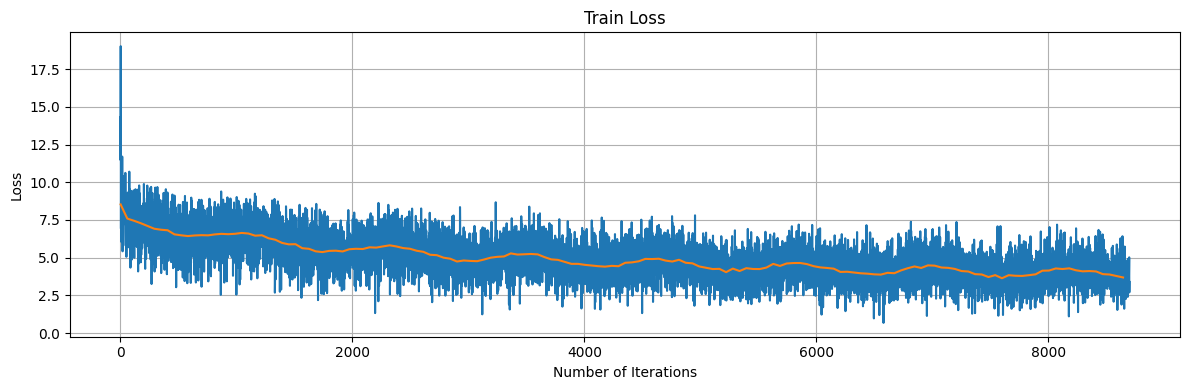

In [ ]:
nrows = 1
_, ax = plt.subplots(nrows, 1, figsize=(12, 4*nrows), tight_layout=True)
ax = np.array([ax]) if not isinstance(ax, np.ndarray) else ax
ax[0].plot(runner.batch_loss, label="Train batch Loss", color="tab:blue")
ax[0].plot(np.arange(1, len(runner.batch_loss)+1, len(runner.train_dataloader)), runner.epoch_loss,
            color="tab:orange", label="Train epoch Loss")
ax[0].grid()
ax[0].set_title("Train Loss")
ax[0].set_xlabel("Number of Iterations")
ax[0].set_ylabel("Loss")

In [ ]:
map_val = runner.validate()
print(f'mAP on test dataset = {map_val:.4f}')

Running validation:   0%|          | 0/17 [00:00<?, ?it/s]

mAP on test dataset = 0.0510
